# Previsão do Ano e da Década de Lançamento da Música
Por: **Sofia Barroso**, **José Morais**, **Francisco Guedes**, **Sahar Bibi-Roubi**
## Índice
* Capítulo I
  * Introdução
  * Definição do Problema
  * Descrição dos Dados
* Capítulo II
  * Data Wrangling
* Capítulo III
  * Data Visualization
* Capítulo IV
  * Aplicação de Modelos de Machine Learning
      * Previsão do Ano de Lançamento da Música
      * Previsão da Década/Época da Música
* Capítulo V
  * Conclusão

    


## Capítulo I

### Introdução

A música é uma manifestação cultural e artística milenar que transcende fronteiras, épocas e linguagens, unindo a humanidade através de padrões sonoros que combinam harmonia, melodia e ritmo. Com origens que remontam aos primórdios da civilização, a criação musical assenta na combinação estruturada de vibrações acústicas ao longo do tempo. O som que escutamos resulta da interação entre diferentes componentes físicos e perceptivos que definem a identidade única de cada gravação.

No processamento e análise do sinal de áudio, uma onda sonora decompõe-se em quatro dimensões fundamentais:
* **Altura (Pitch):** A frequência fundamental que define se uma nota é percecionada como grave ou aguda.
* **Intensidade (Loudness):** A amplitude da onda sonora, relacionada com a força, energia e dinâmica do volume reproduzido.
* **Duração:** A persistência temporal do som e dos seus silêncios, estruturando o andamento e o compasso rítmico.
* **Timbre:** A "cor" ou textura da onda acústica. É a propriedade que nos permite distinguir instantaneamente uma mesma nota tocada por um piano, uma guitarra elétrica ou a voz humana, dependendo da sua envolvente e distribuição harmónica.

Esta diversidade de elementos físicos e a combinação infinita de arranjos fazem com que a música, embora sustentada em princípios matemáticos e físicos bem definidos, seja um dos domínios artísticos mais ricos e complexos da perceção humana.

Com o desenvolvimento das tecnologias, a Inteligência Artificial (IA) e a Ciência de Dados têm vindo a revelar-se ferramentas promissoras para explorar esta complexidade. A área de Recuperação de Informação Musical (*Music Information Retrieval* - MIR) é hoje um dos ramos mais investigados, recorrendo à extração de padrões espectrais e tímbricos para analisar, catalogar e prever atributos sonoros. A necessidade de descodificar centenas de frequências simultâneas e variações de produção fornece um ambiente desafiador ideal para treinar modelos preditivos de Aprendizagem Automática, permitindo associar a evolução acústica de estúdio à linha temporal em que as obras foram criadas.

### Definição do Problema

Ao contrário de outros problemas de previsão no domínio musical que dependem de informações explícitas e triviais como o nome do artista, o título do álbum ou o género atribuído, prever o período temporal de uma obra exclusivamente através do sinal sonoro é um desafio dinâmico e complexo. O estilo de composição, a acústica das gravações e os hábitos de produção em estúdio alteram-se com o passar das décadas, tornando a identificação temporal uma tarefa analítica rigorosa.

As características recolhidas sobre cada gravação abrangem um conjunto variado de propriedades sonoras que podem influenciar a identificação do momento temporal da obra:
* **Médias Tímbricas:** Capturam o equilíbrio espectral médio, a distribuição de frequências predominantes e a coloração tonal do sinal, refletindo a instrumentação utilizada e as escolhas de equalização típicas de cada período.
* **Covariâncias Tímbricas:** Retratam a dinâmica sonora, o contraste e a textura ao longo da reprodução da faixa, evidenciando avanços técnicos como o recurso a gravações multipista, novas técnicas de compressão de gama dinâmica e o aparecimento de instrumentos eletrónicos e sintetizadores.

A nossa abordagem envolve a aplicação das bibliotecas científicas para explorar, limpar e analisar estruturalmente estas variáveis sonoras. Através de técnicas de análise exploratória de dados e da posterior implementação de modelos de Aprendizagem Automática Supervisionada tanto para prever de forma contínua o ano exato de lançamento como para categorizar as faixas por décadas ou épocas, procuramos identificar padrões acústicos consistentes e quantificar o impacto destas propriedades tímbricas na datação das obras musicais.

### Descrição dos Dados

| Atributo | Designação | Tipo de Dado | Descrição e Interpretação |
| :--- | :--- | :--- | :--- |
| `Coluna 0` | Ano de Lançamento | Numérico Inteiro (`int64`) | Variável alvo (*target*). Representa o ano oficial de lançamento da obra musical (compreendido entre 1922 e 2011). |
| `Colunas 1 a 12` | Médias Tímbricas | Numérico Contínuo (`float64`) | Médias aritméticas calculadas sobre os 12 coeficientes tímbricos ao longo de todos os segmentos da faixa. Refletem a distribuição espectral média e o equilíbrio tonal global. |
| `Colunas 13 a 90` | Covariâncias Tímbricas | Numérico Contínuo (`float64`) | Matriz de covariância (78 valores) entre os 12 coeficientes de timbre ao longo da faixa. Retratam a dinâmica temporal, contrastes acústicos e variações de textura sonora. |

## Capítulo II

### Data Wrangling

Iremos importar as bibliotecas necessárias para o nosso estudo.


In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Importamos o dataset



In [5]:
dataframe = pd.read_csv('YearPredictionMSD.txt', sep=',', header=None)
dataframe.head()

,0,1,2,3,4,5,6,7,8,9,...,81,82,83,84,85,86,87,88,89,90
0,2001,49.94357,21.47114,73.07750,8.74861,-17.40628,-13.09905,-25.01202,-12.23257,7.83089,...,13.01620,-54.40548,58.99367,15.37344,1.11144,-23.08793,68.40795,-1.82223,-27.46348,2.26327
1,2001,48.73215,18.42930,70.32679,12.94636,-10.32437,-24.83777,8.76630,-0.92019,18.76548,...,5.66812,-19.68073,33.04964,42.87836,-9.90378,-32.22788,70.49388,12.04941,58.43453,26.92061
2,2001,50.95714,31.85602,55.81851,13.41693,-6.57898,-18.54940,-3.27872,-2.35035,16.07017,...,3.03800,26.05866,-50.92779,10.93792,-0.07568,43.20130,-115.00698,-0.05859,39.67068,-0.66345
3,2001,48.24750,-1.89837,36.29772,2.58776,0.97170,-26.21683,5.05097,-10.34124,3.55005,...,34.57337,-171.70734,-16.96705,-46.67617,-12.51516,82.58061,-72.08993,9.90558,199.62971,18.85382
4,2001,50.97020,42.20998,67.09964,8.46791,-15.85279,-16.81409,-12.48207,-9.37636,12.63699,...,9.92661,-55.95724,64.92712,-17.72522,-1.49237,-7.50035,51.76631,7.88713,55.66926,28.74903


Vericamos o tamanho do dataset, número de instâncias x número de features.

In [6]:
dataframe.shape

(515345, 91)

Ao avaliarmos a quantidade de NaN existentes, concluímos que não existem dados em falta.

In [7]:
dataframe.isnull().sum()

0     0
1     0
2     0
3     0
4     0
     ..
86    0
87    0
88    0
89    0
90    0
Length: 91, dtype: int64

Verificamos se existem linhas repetidas no conjunto de dados


In [11]:
dataframe.duplicated().sum()


np.int64(214)

Identificaram-se 214 registos duplicados (cerca de 0,04% do total de dados). Removemos estas linhas para eliminar ruído e prevenir fuga de informação nos modelos futuros.

In [14]:
dataframe = dataframe.drop_duplicates()


Criação de uma cópia independente dos dados brutos para fazer transformações de forma segura.

In [15]:
data = dataframe.copy()

Atribuímos designações às 91 variáveis: a variável alvo 'year', 12 médias tímbricas e 78 covariâncias tímbricas.

In [16]:
col_names = ['year'] + [f'timbre_avg_{i}' for i in range(1, 13)] + [f'timbre_cov_{i}' for i in range(1, 79)]
data.columns = col_names
data.head()

,year,timbre_avg_1,timbre_avg_2,timbre_avg_3,timbre_avg_4,timbre_avg_5,timbre_avg_6,timbre_avg_7,timbre_avg_8,timbre_avg_9,...,timbre_cov_69,timbre_cov_70,timbre_cov_71,timbre_cov_72,timbre_cov_73,timbre_cov_74,timbre_cov_75,timbre_cov_76,timbre_cov_77,timbre_cov_78
0,2001,49.94357,21.47114,73.07750,8.74861,-17.40628,-13.09905,-25.01202,-12.23257,7.83089,...,13.01620,-54.40548,58.99367,15.37344,1.11144,-23.08793,68.40795,-1.82223,-27.46348,2.26327
1,2001,48.73215,18.42930,70.32679,12.94636,-10.32437,-24.83777,8.76630,-0.92019,18.76548,...,5.66812,-19.68073,33.04964,42.87836,-9.90378,-32.22788,70.49388,12.04941,58.43453,26.92061
2,2001,50.95714,31.85602,55.81851,13.41693,-6.57898,-18.54940,-3.27872,-2.35035,16.07017,...,3.03800,26.05866,-50.92779,10.93792,-0.07568,43.20130,-115.00698,-0.05859,39.67068,-0.66345
3,2001,48.24750,-1.89837,36.29772,2.58776,0.97170,-26.21683,5.05097,-10.34124,3.55005,...,34.57337,-171.70734,-16.96705,-46.67617,-12.51516,82.58061,-72.08993,9.90558,199.62971,18.85382
4,2001,50.97020,42.20998,67.09964,8.46791,-15.85279,-16.81409,-12.48207,-9.37636,12.63699,...,9.92661,-55.95724,64.92712,-17.72522,-1.49237,-7.50035,51.76631,7.88713,55.66926,28.74903


Criamos a coluna decade para a década e a coluna era_class com np.where para classificar a época da música.

In [17]:
data['decade'] = (data['year'] // 10) * 10
data['era_class'] = np.where(data['year'] >= 2000, 'Modern', 'Classic_Vintage')
data[['year', 'decade', 'era_class']].head()

,year,decade,era_class
0,2001,2000,Modern
1,2001,2000,Modern
2,2001,2000,Modern
3,2001,2000,Modern
4,2001,2000,Modern


Analisamos a distribuição de frequências absolutas da variável qualitativa 'era_class' para verificar a proporção de músicas em cada época.

In [18]:
data['era_class'].value_counts()

era_class
Modern             308261
Classic_Vintage    206870
Name: count, dtype: int64

Calculamos as estatísticas descritivas para a variável alvo 'year', a variável derivada 'decade' e a componente principal 'timbre_avg_1' transpondo a tabela para facilitar a leitura.

In [23]:
colunas_principais = ['year', 'decade', 'timbre_avg_1']
est_descritiva = data[colunas_principais].describe().transpose()
est_descritiva

,count,mean,std,min,25%,50%,75%,max
year,515131.0,1998.396305,10.931629,1922.000,1994.000000,2002.00000,2006.000000,2011.00000
decade,515131.0,1993.375996,10.816516,1920.000,1990.000000,2000.00000,2000.000000,2010.00000
timbre_avg_1,515131.0,43.386256,6.067919,1.749,39.953445,44.25711,47.833585,61.97014


## Capítulo III

### Data Visualization



Neste capítulo exploramos visualmente os dados com o objetivo de compreender a distribuição da variável alvo 'year', o equilíbrio das classes criadas 'era_class' e a relação entre o tempo e as características sonoras 'timbre_avg_1'.

Construímos um histograma para analisar a distribuição da variável contínua 'year', verificando a frequência das observações ao longo do intervalo temporal coberto pelo conjunto de dados.

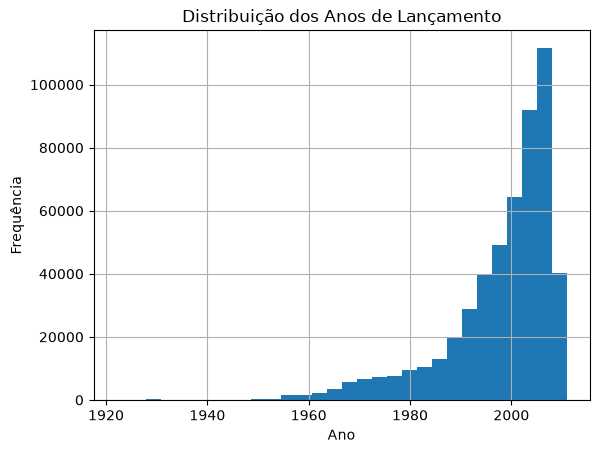

In [24]:
plt.figure()
plt.hist(data['year'], bins=30)
plt.title('Distribuição dos Anos de Lançamento')
plt.xlabel('Ano')
plt.ylabel('Frequência')
plt.grid()
plt.show()

##### Interpretação do Gráfico:
O eixo horizontal ($X$) apresenta o ano de lançamento das faixas (abrangendo desde 1922 até 2011), dividido em 30 intervalos (*bins*). O eixo vertical ($Y$) indica a contagem absoluta (frequência) de músicas registadas em cada período.
Observa-se  então uma distribuição fortemente enviesada à esquerda (*left-skewed*), com uma concentração exponencial de dados nas décadas mais recentes. O pico de volume ocorre claramente entre o final dos anos 1990 e meados dos anos 2000 (atingindo mais de 110.000 observações no intervalo com maior densidade).
O catálogo anterior a 1960 apresenta uma representação residual na amostra global, o que evidencia um desbalanceamento temporal relevante a ter em consideração na fase de modelação preditiva (Machine Learning).

Construímos um gráfico de barras  para visualizar a distribuição de frequências da variável qualitativa nominal 'era_class', comparando o volume de faixas modernas com as faixas clássicas.

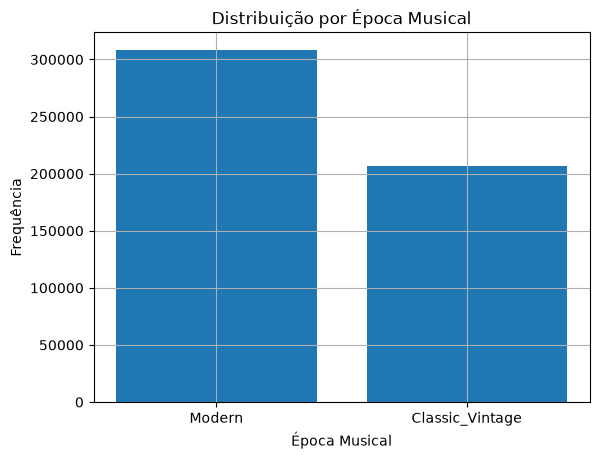

In [25]:
contagem_era = data['era_class'].value_counts()

plt.figure()
plt.bar(contagem_era.index, contagem_era.values)
plt.title('Distribuição por Época Musical')
plt.xlabel('Época Musical')
plt.ylabel('Frequência')
plt.grid()
plt.show()

##### Interpretação do Gráfico:
O eixo horizontal ($X$) identifica as duas categorias da variável qualitativa 'era_class', 'Modern' e 'Classic_Vintage'. O eixo vertical ($Y$) quantifica a frequência absoluta (número total de músicas) correspondente a cada classe.
A barra associada a 'Modern' ultrapassa ligeiramente a marca das 300.000 músicas, revelando-se a categoria com maior representatividade no conjunto de dados.
A categoria 'Classic_Vintage' situa-se logo acima das 200.000 observações, demonstrando uma presença substancial.
O gráfico evidencia visualmente que as duas classes apresentam uma dimensão comparável (numa proporção aproximada de 3 para 2), confirmando que a agregação temporal permite balancear a distribuição para a classificação supervisionada.

Construímos um gráfico de dispersão para analisar a relação entre a variável contínua temporal 'year' e a componente acústica principal 'timbre_avg_1' (intensidade/volume sonoro médio). Para garantir a legibilidade visual e eficiência computacional, recorremos a uma amostra aleatória de 5.000 observações.

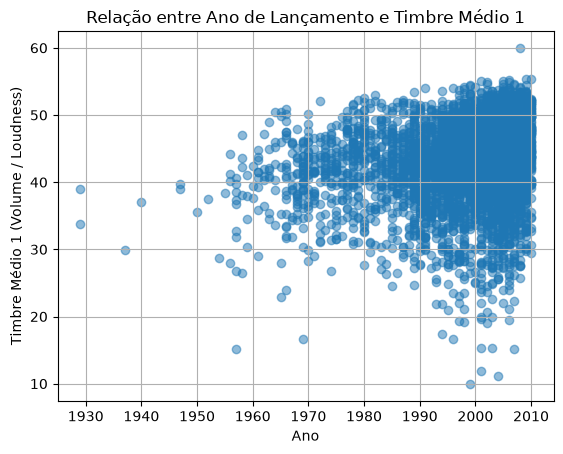

In [27]:
amostra = data.sample(n=5000, random_state=42)

plt.figure()
plt.scatter(amostra['year'], amostra['timbre_avg_1'], alpha=0.5)
plt.title('Relação entre Ano de Lançamento e Timbre Médio 1')
plt.xlabel('Ano')
plt.ylabel('Timbre Médio 1 (Volume / Loudness)')
plt.grid()
plt.show()

##### Interpretação do Gráfico:
O eixo horizontal ($X$) identifica o ano de lançamento das músicas (desde aproximadamente 1930 até 2010), enquanto o eixo vertical ($Y$) indica a primeira componente tímbrica,'Timbre Médio 1', representativa do volume/intensidade sonora média (*loudness*), em valores que variam entre 10 e 60. Cada ponto circular corresponde a uma música da amostra selecionada.
A densidade dos pontos espelha a distribuição do catálogo, verificando-se assim uma presença muito dispersa e escassa de faixas antes de 1960/1970, contrastando com uma forte concentração visual a partir dos anos 1990 e 2000.
Observa-se uma tendência clara de subida do teto superior da nuvem de pontos ao longo das décadas: nos anos mais antigos o limite superior situava-se abaixo de 40–45, ao passo que nos anos 2000 atinge consistentemente valores entre 50 e quase 60.
Este padrão evidencia a evolução histórica da produção musical, onde as gravações foram ficando progressivamente mais altas e comprimidas, confirmando que esta variável acústica guarda uma relação temporal útil para prever o ano da música.